<a href="https://colab.research.google.com/github/G30RG3AG/ab-testing-landing-page/blob/main/S9_Version_Student_Proyecto_Landing_Experiment_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency


In [ ]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
display(df.head())

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario**:

El dataset contiene **40,000 registros y 9 columnas**. En la revisión inicial mediante `df.info()`, no se identificaron valores ausentes, ya que todas las columnas contienen 40,000 valores no nulos.

Se observó que la columna `date` se encontraba almacenada como tipo `object`, por lo que se realizará su conversión al tipo `datetime` para facilitar el análisis temporal. Las columnas `converted` y `gasto` presentan tipos de datos numéricos adecuados para el análisis estadístico.

Adicionalmente, se verificarán los registros duplicados y las fechas inválidas para asegurar la calidad de los datos antes de continuar con el experimento A/B.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [ ]:

usuarios_unicos = df["user_id"].nunique()

print("Cantidad de usuarios únicos:", usuarios_unicos)
print("Cantidad total de registros:", len(df))

Cantidad de usuarios únicos: 40000
Cantidad total de registros: 40000


 **Variable `date`**  
Explorar rango de fechas

In [ ]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [ ]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
print("Resumen estadístico de gasto:")
print(df["gasto"].describe())

Resumen estadístico de gasto:
count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64


In [ ]:
# Resumen estadístico de usuarios que se convirtieron
print("\nResumen de gasto de usuarios convertidos:")
print(df.loc[df["converted"] == 1, "gasto"].describe())


Resumen de gasto de usuarios convertidos:
count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")

columnas_categoricas = [
    "landing",
    "region",
    "dispositivo",
    "traffic_source",
    "user_type"
]

for columna in columnas_categoricas:
    print(f"\n{columna}:")
    print(df[columna].value_counts())


Conteo de categorías:

landing:
B    20018
A    19982
Name: landing, dtype: int64

region:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

dispositivo:
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

traffic_source:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

user_type:
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


In [ ]:
print("\nConteo de versiones de landing:")
print(df["landing"].value_counts())

print("\nProporción de versiones de landing:")
print(df["landing"].value_counts(normalize=True) * 100)



Conteo de versiones de landing:
B    20018
A    19982
Name: landing, dtype: int64

Proporción de versiones de landing:
B    50.045
A    49.955
Name: landing, dtype: float64


✍️ **Comentario**: La variable gasto presenta una media de 9.33 considerando a todos los usuarios y de 65.37 entre quienes se convirtieron. Los cuartiles de gasto general son iguales a cero, lo que indica que la mayoría de los registros no presenta gasto.

Las variables categóricas contienen las categorías observadas esperadas para el experimento. Las versiones A y B cuentan con 19,982 y 20,018 registros, respectivamente, por lo que la asignación está prácticamente equilibrada.

Como validación adicional, se comprobarán los valores negativos, la consistencia entre conversión y gasto, y los posibles valores inesperados. Una vez completadas estas verificaciones, se podrá continuar con la comparación estadística de ambas versiones de la página de inicio.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:

# Gasto por versión: solo usuarios que se convirtieron
gasto_A = df[(df["landing"] == "A") & (df["converted"] == 1)]["gasto"]
gasto_B = df[(df["landing"] == "B") & (df["converted"] == 1)]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)


(2512, 3194)

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios convertidos es igual para las páginas A y B.
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios convertidos es diferente entre las páginas A y B.

In [ ]:
t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico t: {t_stat:.4f}")
print(f"Valor p: {p_value:.6f}")

Estadístico t: -9.4810
Valor p: 0.000000


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (H₀), ya que el valor p es menor que el nivel de significancia de 0.05. Por lo tanto, existe evidencia estadísticamente significativa de una diferencia en el gasto promedio de los usuarios convertidos entre las páginas A y B.

**Interpretación de negocio:**  
Los resultados indican que existe una diferencia significativa en el gasto promedio de los clientes que vieron cada versión de la página de inicio. El estadístico t negativo (\(-9.4810\)) indica que el promedio del grupo A es menor que el del grupo B. Por lo tanto, la página B presenta un mayor gasto promedio entre los usuarios convertidos, lo que podría representar una oportunidad para generar mayor valor económico para el negocio.
Sin embargo, antes de recomendar definitivamente la página B, también es necesario analizar las tasas de conversión de ambas versiones, ya que una página puede generar un mayor gasto promedio entre quienes compran, pero convertir a menos visitantes en clientes.


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual en las páginas A y B.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre las páginas A y B

In [ ]:

# Número de usuarios convertidos por página
convertidos = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", convertidos)
print("\nTotal de usuarios por página:\n", totales)



Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [ ]:

from statsmodels.stats.proportion import proportions_ztest

# Número de usuarios convertidos por página
convertidos = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales = df.groupby("landing")["converted"].count()

# Aplicar prueba z para dos proporciones
conteos = [convertidos["A"], convertidos["B"]]
n_observaciones = [totales["A"], totales["B"]]

z_stat, p_value = proportions_ztest(
    count=conteos,
    nobs=n_observaciones,
    alternative="two-sided"
)

# Visualizar resultados
print(f"Estadístico z: {z_stat:.4f}")
print(f"Valor p: {p_value:.6f}")


Estadístico z: -9.6774
Valor p: 0.000000


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (H₀), porque el valor p es menor que el nivel de significancia de 0.05. Existe evidencia estadísticamente significativa de una diferencia entre las tasas de conversión de las páginas A y B.

**Interpretación de negocio:**  
La página B supera a la página A por aproximadamente 3.38 puntos porcentuales. Además, el estadístico z negativo (\(-9.6774\)) se debe al orden de comparación A menos B, lo que indica que la proporción de conversiones de A es menor que la de B.
En términos de negocio, la página B es la opción más favorable para generar conversiones, porque una mayor proporción de los usuarios que la visitaron se convirtió en cliente. Este resultado, junto con el mayor gasto promedio observado anteriormente entre los usuarios convertidos, favorece a la página B en los dos indicadores analizados.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...
Hipótesis nula (H₀): No existe una asociación estadísticamente significativa entre la fuente de tráfico (traffic_source) y la conversión (converted). Ambas variables son independientes.



Hipótesis alternativa (H₁): Existe una asociación estadísticamente significativa entre la fuente de tráfico y la conversión. Ambas variables no son independientes.

In [ ]:
# Aplicar prueba

from scipy.stats import chi2_contingency

# Crear tabla de contingencia
tabla_trafico = pd.crosstab(df["traffic_source"], df["converted"])

print("Tabla de contingencia:")
print(tabla_trafico)

# Aplicar prueba chi-cuadrado
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_trafico)

# Visualizar resultados
print(f"\nEstadístico chi-cuadrado: {chi2_stat:.4f}")
print(f"Valor p: {p_value:.6f}")

# Tomar una decisión con un nivel de significancia de 0.05
alpha = 0.05

if p_value < alpha:
    print("Rechazamos H0: existe una asociación significativa entre la fuente de tráfico y la conversión.")
else:
    print("No rechazamos H0: no hay evidencia suficiente de una asociación significativa.")




Tabla de contingencia:
converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

Estadístico chi-cuadrado: 8.6621
Valor p: 0.034138
Rechazamos H0: existe una asociación significativa entre la fuente de tráfico y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula (H₀), porque el valor p de 0.034138 es menor que el nivel de significancia de 0.05. Existe evidencia estadísticamente significativa de una asociación entre la fuente de tráfico (traffic_source) y la conversión (converted).

**Interpretación de negocio:**  
En términos de negocio, conviene evaluar la eficiencia de cada canal, no solamente el volumen de conversiones. Email podría ser interesante para optimizar la conversión, mientras que Organic destaca por su capacidad de atraer usuarios y generar un mayor número de clientes. Antes de reasignar presupuesto, también sería necesario comparar los costos de adquisición y el valor económico generado por cada canal.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

Hipótesis:
- Hipótesis nula (H₀): No existe una asociación estadísticamente significativa entre el tipo de usuario (user_type) y la conversión (converted). Ambas variables son independientes.
- Hipótesis alternativa (H₁): Existe una asociación estadísticamente significativa entre el tipo de usuario y la conversión. Ambas variables no son independientes.

In [ ]:
# Aplicar prueba

from scipy.stats import chi2_contingency

# Crear tabla de contingencia
tabla_usuarios = pd.crosstab(df["user_type"], df["converted"])

print("Tabla de contingencia:")
print(tabla_usuarios)

# Aplicar prueba chi-cuadrado
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_usuarios)

# Visualizar resultados
print(f"\nEstadístico chi-cuadrado: {chi2_stat:.4f}")
print(f"Valor p: {p_value:.6f}")

# Tomar una decisión con un nivel de significancia de 0.05
alpha = 0.05

if p_value < alpha:
    print("Rechazamos H0: existe una asociación significativa entre el tipo de usuario y la conversión.")
else:
    print("No rechazamos H0: no hay evidencia suficiente de una asociación significativa.")




Tabla de contingencia:
converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968

Estadístico chi-cuadrado: 0.5135
Valor p: 0.473634
No rechazamos H0: no hay evidencia suficiente de una asociación significativa.


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula (H₀), ya que el valor p de 0.473634 es mayor que el nivel de significancia de 0.05. Por lo tanto, no existe evidencia estadística suficiente para afirmar que haya una asociación entre el tipo de usuario (user_type) y la conversión (converted).

**Interpretación de negocio:**  
Desde el punto de vista del negocio, no hay evidencia suficiente para afirmar que uno de estos perfiles convierta mejor que el otro. Por ello, no sería recomendable priorizar usuarios nuevos o recurrentes únicamente con base en estos resultados; conviene considerar otras variables, como la fuente de tráfico, el dispositivo y la versión de la página de inicio.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

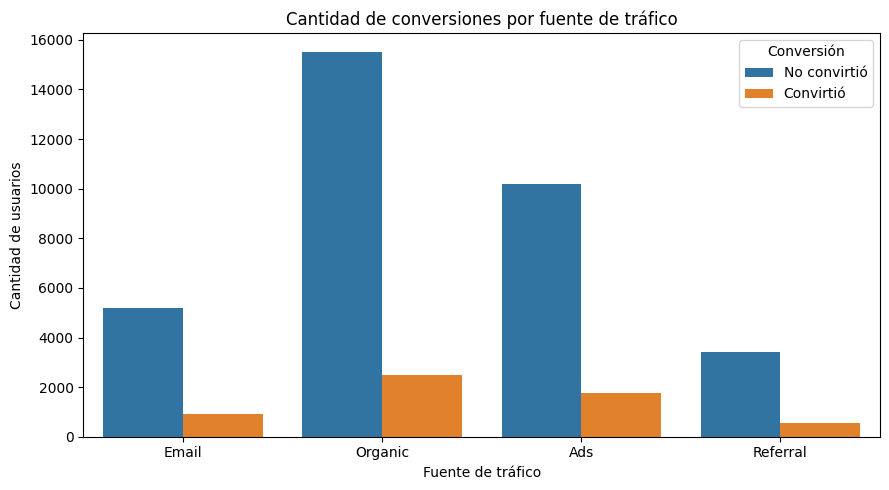

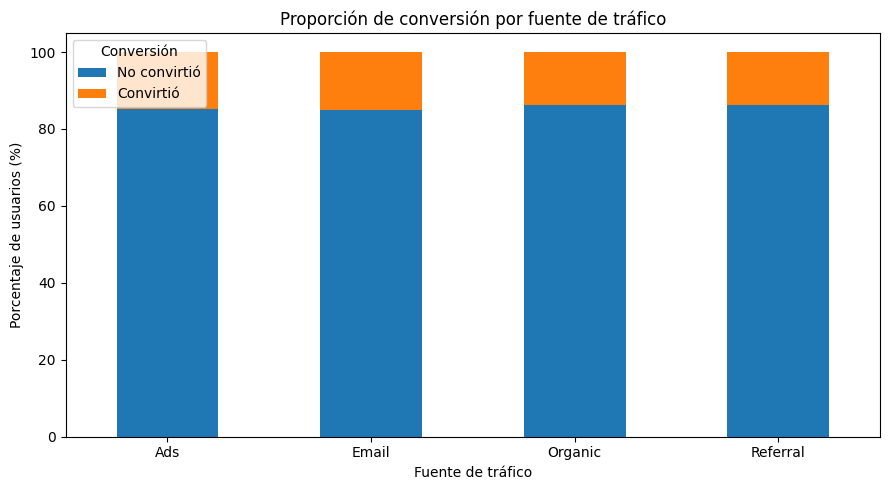

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Cantidades absolutas
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="traffic_source", hue="converted")
plt.title("Cantidad de conversiones por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Cantidad de usuarios")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])
plt.tight_layout()
plt.show()

# Proporciones por fuente de tráfico
tabla_trafico_pct = pd.crosstab(
    df["traffic_source"],
    df["converted"],
    normalize="index"
) * 100

tabla_trafico_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)
plt.title("Proporción de conversión por fuente de tráfico")
plt.xlabel("Fuente de tráfico")
plt.ylabel("Porcentaje de usuarios (%)")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


✍️ **Comentario**:
Gráfico 1: Cantidad de conversiones por fuente de tráfico   Descripción:Este gráfico muestra el volumen absoluto de usuarios segmentados por su canal de adquisición (Organic, Ads, Email y Referral) y su estado de conversión.   Volumen por canal: Organic (Tráfico Orgánico) genera el mayor volumen total de usuarios y de conversiones absolutas (aproximadamente 2,500 conversiones), seguido de cerca por Ads (Publicidad pagada) con cerca de 1,800 conversiones.   Canales con menor tracción: Email y Referral aportan una cantidad considerablemente menor tanto en tráfico como en conversiones absolutas.   

✍️ **Comentario**:
Gráfico 2: Proporción de conversión por fuente de tráfico   Descripción:Este gráfico de barras apiladas al 100% contrasta la tasa de conversión relativa (porcentaje) de cada fuente de tráfico.   Rendimiento homogéneo: Al igual que en el análisis por tipo de usuario, las tasas de conversión relativas son prácticamente idénticas en todas las fuentes de adquisición.   Desglose porcentual: Independientemente de si el usuario proviene de Ads, Email, Organic o Referral, la tasa de conversión se mantiene estable en torno al 14%, con un 86% de no conversión en cada canal.   Conclusión estratégica: Ningún canal cuenta intrínsecamente con una "mejor optimización" o mayor efectividad porcentual para convertir usuarios; el alto volumen de conversiones en canales como Organic o Ads se debe estrictamente a que captan un mayor volumen de tráfico en comparación con Email y Referral.   

### Relación entre el tipo de usuario y la conversión

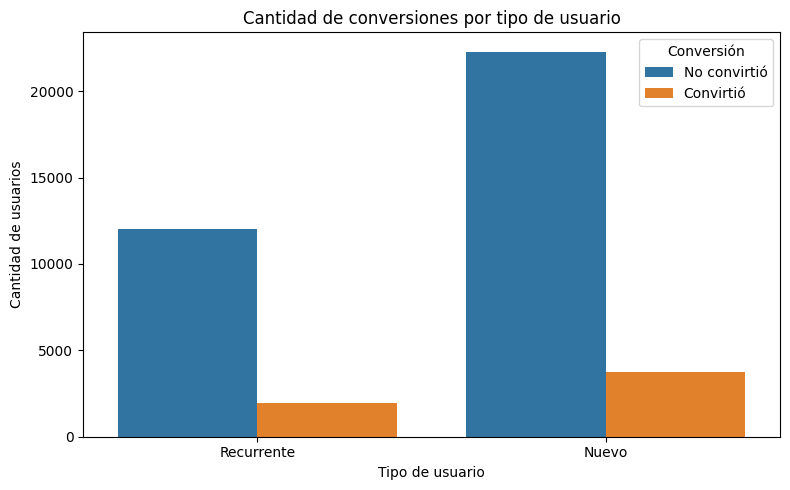

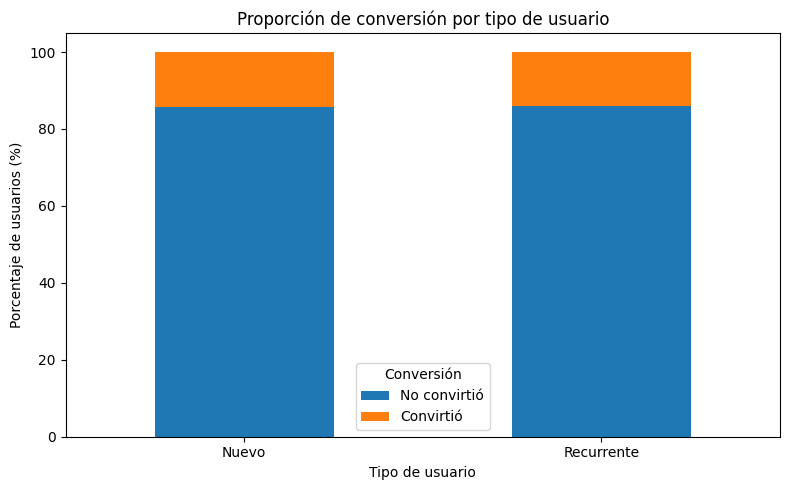

In [ ]:

# Cantidades absolutas
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="user_type", hue="converted")
plt.title("Cantidad de conversiones por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Cantidad de usuarios")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])
plt.tight_layout()
plt.show()

# Proporciones por tipo de usuario
tabla_usuario_pct = pd.crosstab(
    df["user_type"],
    df["converted"],
    normalize="index"
) * 100

tabla_usuario_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)
plt.title("Proporción de conversión por tipo de usuario")
plt.xlabel("Tipo de usuario")
plt.ylabel("Porcentaje de usuarios (%)")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


✍️ **Comentario**:
Gráfico 1: Cantidad de conversiones por tipo de usuario   Descripción:Este gráfico de barras agrupadas muestra el número absoluto de usuarios segmentados según su tipo (Recurrente o Nuevo) y su estado de conversión (No convirtió en azul vs. Convirtió en naranja).   Volumen total: Los usuarios de tipo Nuevo representan un volumen significativamente mayor en comparación con los usuarios de tipo Recurrente.   Conversión absoluta: Aunque la mayoría de los usuarios de ambos grupos no realiza una conversión, la cantidad total de usuarios que sí convirtieron es notablemente superior en el grupo de usuarios Nuevos (alrededor de 3,800 a 4,000 conversiones) en comparación con los Recurrentes (aproximadamente 2,000 conversiones).  

✍️ **Comentario**:
Gráfico 2: Proporción de conversión por tipo de usuario   Descripción:Este gráfico de barras apiladas al 100% permite comparar la tasa de conversión relativa (porcentaje) entre los usuarios Nuevos y los Recurrentes.   Tasa de conversión homogénea: Al analizar los datos en términos porcentuales, se observa que la proporción de conversión es prácticamente idéntica entre ambos segmentos.   Desglose: Para ambos tipos de usuarios, aproximadamente el 86% no convierte (sección azul), mientras que solo cerca del 14% logra convertir (sección naranja).   Conclusión clave: La mayor cantidad de conversiones observada en los usuarios Nuevos (Gráfico 1) se debe a que representan un volumen de tráfico mayor, y no a que tengan una efectividad o tasa de conversión superior a la de los usuarios Recurrentes.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
* La **Página B** genera un **gasto promedio estadísticamente mayor** entre los usuarios convertidos en comparación con la Página A.
* La prueba t de Student confirmó una diferencia significativa ($p < 0.05$, estadístico $t = -9.4810$), demostrando que los clientes expuestos a la versión B invierten más al concretar una compra.
* **Interpretación:** La Página B no solo atrae más transacciones, sino que maximiza el valor económico (ticket promedio) aportado por cada cliente.

**Tasa de conversión:**
* La **Página B** presenta una **tasa de conversión superior** a la Página A, superándola por aproximadamente **3.38 puntos porcentuales** (15.95% frente a 12.57%).
* La prueba z para dos proporciones validó que esta diferencia es estadísticamente significativa ($p < 0.05$, estadístico $z = -9.6774$).
* **Interpretación:** La versión B es marcadamente más efectiva para persuadir a los visitantes de completar una conversión. Al unir este resultado con el mayor gasto promedio, la Página B resulta superior en los dos indicadores clave de rendimiento del negocio.

---

#### 📊 **Segmentación por fuente de tráfico**
* Se identificó una **asociación estadísticamente significativa** entre la fuente de tráfico y la conversión ($\chi^2 = 8.6621$, $p = 0.0341$).
* **Interpretación:** El canal **Organic (Orgánico)** destaca de forma masiva como el principal motor de tráfico y conversiones absolutas (~2,480 conversiones), seguido de cerca por **Ads** (~1,759 conversiones). Aunque las tasas de conversión relativas por canal rondan de manera estable el 14%, los canales orgánicos y de pauta concentran el volumen operativo clave para el crecimiento.

---

#### 📊 **Segmentación por tipo de usuario**
* **No se encontró una asociación estadísticamente significativa** entre el tipo de usuario (Nuevo vs. Recurrente) y la tasa de conversión ($\chi^2 = 0.5135$, $p = 0.4736$).
* **Interpretación:** Aunque los usuarios **Nuevos** generan un volumen absoluto superior de conversiones, esto ocurre estrictamente porque representan una mayor proporción del tráfico total. Su efectividad porcentual para convertir es equivalente a la de los usuarios recurrentes (ambos alrededor del 14%), por lo que no se requiere una segmentación diferenciada de landing page basada únicamente en esta categoría.

---

#### 💡 **Recomendaciones de negocio:**
* **Implementar la Página B como versión definitiva:** Sustituir la versión A por la versión B en la página de inicio, ya que optimiza tanto la conversión de visitantes como el valor monetario por cliente.
* **Potenciar la estrategia en canales de alto rendimiento:** Dirigir los esfuerzos de marketing y presupuesto principalmente hacia los canales **Organic** y **Ads**, aprovechando su alta capacidad de atracción de volumen y generación de clientes.